# Netflix Trend Analysis by Release Year

## Objective
This project analyzes Netflix content based on release year to understand how the platform's content library is distributed across different years.

The analysis focuses on yearly release patterns, growth and decline trends, and comparisons between Movies and TV Shows.

## Dataset
The cleaned Netflix dataset is used for this analysis.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("Netflix_Cleaned_Dataset.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
print("Release Year Data Type:")
print(df['release_year'].dtype)

print("\nMissing Release Year Values:")
print(df['release_year'].isnull().sum())

print("\nEarliest Release Year:", df['release_year'].min())
print("Latest Release Year:", df['release_year'].max())

print("\nRelease Year Summary:")
print(df['release_year'].describe())

Release Year Data Type:
int64

Missing Release Year Values:
0

Earliest Release Year: 1925
Latest Release Year: 2021

Release Year Summary:
count    8790.000000
mean     2014.183163
std         8.825466
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64


In [5]:
print("Content Type Distribution:")
print(df['type'].value_counts())

Content Type Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [6]:
# Calculate total Netflix titles by original release year

yearly_content = (
    df.groupby('release_year')['show_id']
    .nunique()
    .reset_index(name='Total Titles')
    .rename(columns={'release_year': 'Release Year'})
    .sort_values('Release Year')
)

yearly_content.head()

,Release Year,Total Titles
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4


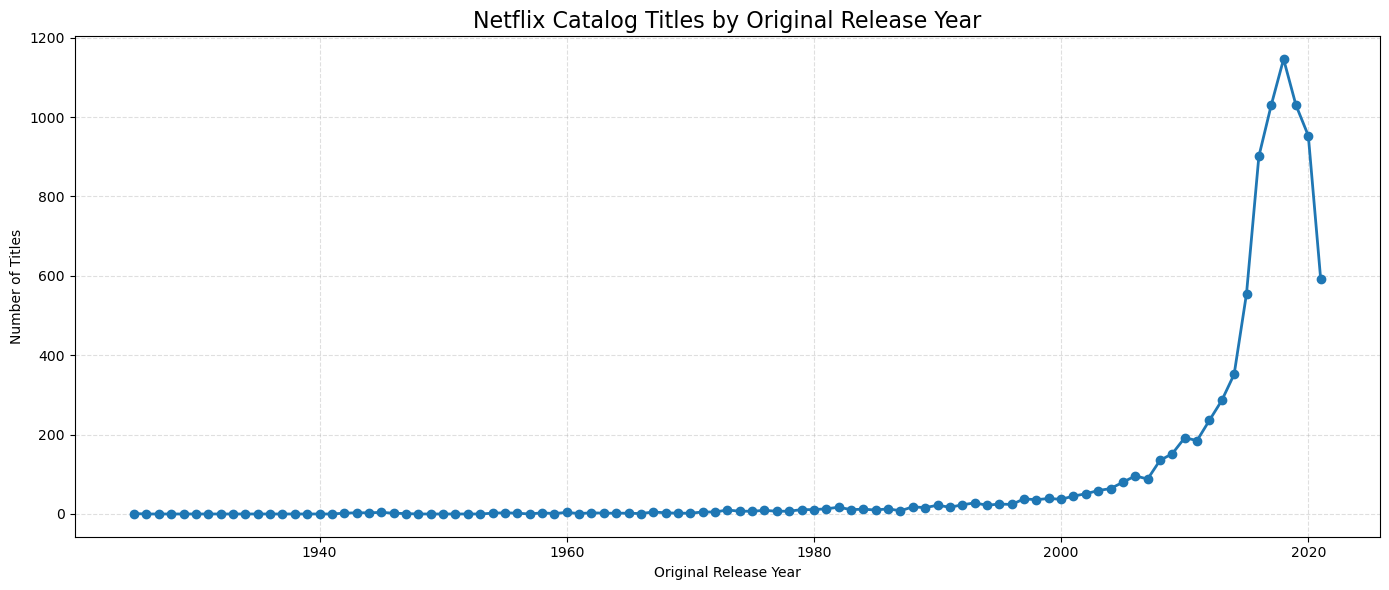

In [7]:
# Include every calendar year in the analysis period
yearly_content_complete = (
    yearly_content
    .set_index('Release Year')
    .reindex(
        range(
            yearly_content['Release Year'].min(),
            yearly_content['Release Year'].max() + 1
        ),
        fill_value=0
    )
    .rename_axis('Release Year')
    .reset_index()
)

# Plot complete year-wise trend
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_content_complete['Release Year'],
    yearly_content_complete['Total Titles'],
    marker='o',
    linewidth=2
)

plt.title('Netflix Catalog Titles by Original Release Year', fontsize=16)
plt.xlabel('Original Release Year')
plt.ylabel('Number of Titles')

plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [8]:
top_release_years = (
    yearly_content
    .sort_values('Total Titles', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("Top 10 Release Years:")
print(top_release_years.to_string(index=False))

Top 10 Release Years:
 Release Year  Total Titles
         2018          1146
         2019          1030
         2017          1030
         2020           953
         2016           901
         2021           592
         2015           555
         2014           352
         2013           286
         2012           236


In [9]:
highest_year = yearly_content.loc[
    yearly_content['Total Titles'].idxmax()
]

lowest_year = yearly_content.loc[
    yearly_content['Total Titles'].idxmin()
]

print("Year with Highest Content Releases:")
print(highest_year)

print("\nYear with Lowest Content Releases:")
print(lowest_year)

Year with Highest Content Releases:
Release Year    2018
Total Titles    1146
Name: 70, dtype: int64

Year with Lowest Content Releases:
Release Year    1925
Total Titles       1
Name: 0, dtype: int64


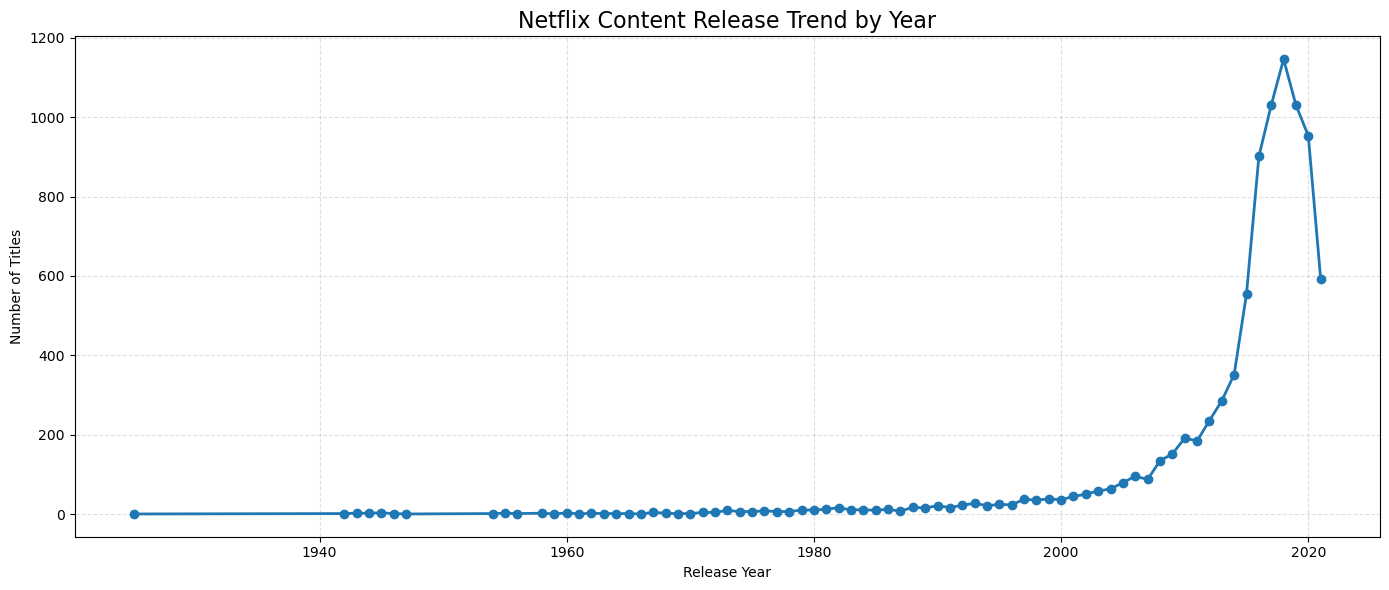

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_content['Release Year'],
    yearly_content['Total Titles'],
    marker='o',
    linewidth=2
)

plt.title('Netflix Content Release Trend by Year', fontsize=16)
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

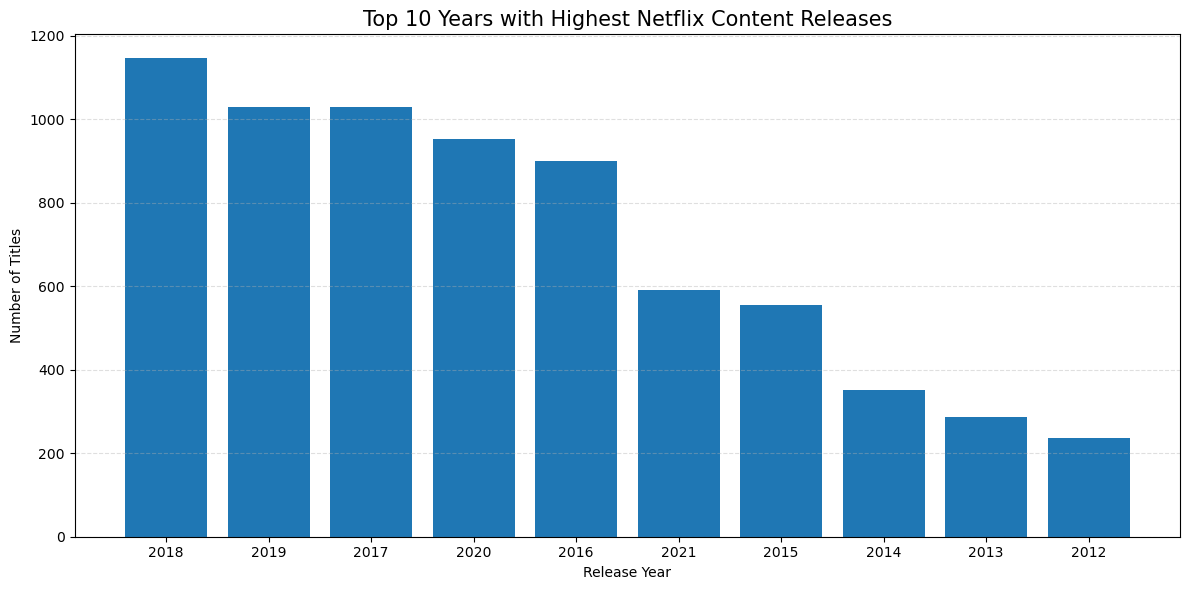

In [11]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_release_years['Release Year'].astype(str),
    top_release_years['Total Titles']
)

plt.title('Top 10 Years with Highest Netflix Content Releases', fontsize=15)
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [12]:
yearly_type = (
    df.groupby(['release_year', 'type'])['show_id']
    .nunique()
    .reset_index(name='Total Titles')
)

yearly_type_pivot = yearly_type.pivot(
    index='release_year',
    columns='type',
    values='Total Titles'
).fillna(0)

yearly_type_pivot.tail(10)

type,Movie,TV Show
release_year,,
2012,173.0,63.0
2013,225.0,61.0
2014,264.0,88.0
2015,396.0,159.0
2016,658.0,243.0
2017,765.0,265.0
2018,767.0,379.0
2019,633.0,397.0
2020,517.0,436.0


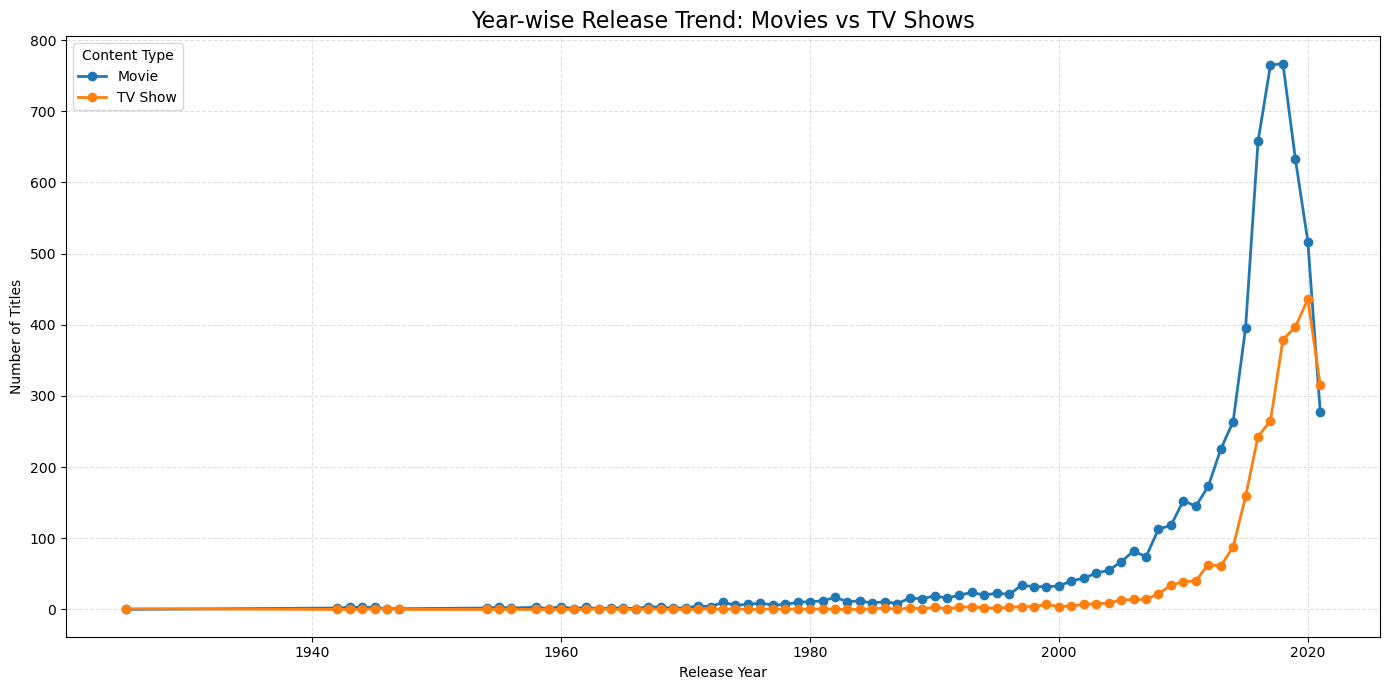

In [13]:
yearly_type_pivot.plot(
    figsize=(14, 7),
    marker='o',
    linewidth=2
)

plt.title('Year-wise Release Trend: Movies vs TV Shows', fontsize=16)
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(title='Content Type')
plt.tight_layout()
plt.show()

In [14]:
for content_type in yearly_type_pivot.columns:
    peak_year = yearly_type_pivot[content_type].idxmax()
    peak_count = yearly_type_pivot[content_type].max()

    print(f"\n{content_type}")
    print("Peak Release Year:", peak_year)
    print("Total Titles:", int(peak_count))


Movie
Peak Release Year: 2018
Total Titles: 767

TV Show
Peak Release Year: 2020
Total Titles: 436


## Key Business Insights

1. **Highest Content Release Year:** 2018 recorded the highest number of Netflix titles, with 1,146 releases.

2. **Movie Release Pattern:** Movies reached their highest release count in 2018, with 767 titles.

3. **TV Show Release Pattern:** TV Shows reached their highest release count in 2020, with 436 titles.

4. **Content Type Comparison:** Movies account for 6,126 titles, while TV Shows account for 2,664 titles. This shows that Movies represent the larger category in the dataset.

5. **Growth in Recent Years:** The charts show a substantial increase in recorded content releases after 2010, with particularly high counts between 2016 and 2020.

6. **2021 Observation:** The number of recorded releases declined in 2021. This result should be interpreted cautiously because the dataset may not include complete information for that year.


## Conclusion

The analysis shows how Netflix catalog titles are distributed by their original release year. Movies represent the larger content category, while TV Shows reached their highest recorded count in 2020. The findings highlight the concentration of titles in recent release years and differences between the two content categories.

**Note:** These results describe the titles available in the dataset, not Netflix's actual annual production or acquisition activity.

In [15]:
print("FINAL TREND ANALYSIS VALIDATION")
print("-" * 40)

print("Total Records:", len(df))
print("Missing Release Years:", df['release_year'].isnull().sum())
print("Unique Release Years:", df['release_year'].nunique())
print("Duplicate Records:", df.duplicated().sum())

print("\nContent Type Distribution:")
print(df['type'].value_counts())

print("\nHighest Overall Release Year:")
print(yearly_content.loc[
    yearly_content['Total Titles'].idxmax()
])

print("\nPeak Release Year by Content Type:")
print(yearly_type_pivot.idxmax())

FINAL TREND ANALYSIS VALIDATION
----------------------------------------
Total Records: 8790
Missing Release Years: 0
Unique Release Years: 74
Duplicate Records: 0

Content Type Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Highest Overall Release Year:
Release Year    2018
Total Titles    1146
Name: 70, dtype: int64

Peak Release Year by Content Type:
type
Movie      2018
TV Show    2020
dtype: int64
